# 4. Chia dữ liệu và chuẩn hóa

Không cần phần trước.

Muốn chạy toàn bộ trong một kernel: [mở notebook 00](00_Gamer_Behavior_Clustering.ipynb).

<details><summary>Danh sách tám phần</summary>

- [1. Tìm hiểu bài toán và dữ liệu](01_data_understanding.ipynb)

- [2. Thống kê và khám phá dữ liệu (EDA)](02_statistics_eda.ipynb)

- [3. Kiểm tra và làm sạch dữ liệu](03_data_cleaning.ipynb)

- [4. Chia dữ liệu và chuẩn hóa](04_data_transformation.ipynb)

- [5. Ward, K-Means và cách kết hợp](05_clustering.ipynb)

- [6. Đánh giá holdout và độ nhạy](06_model_evaluation.ipynb)

- [7. Hồ sơ người chơi và trực quan hóa](07_player_profiling.ipynb)

- [8. Gán người chơi và đề xuất chiến lược](08_prediction_strategy.ipynb)

</details>

## Khởi tạo và đọc dữ liệu

In [1]:
from pathlib import Path
import os, sys, json, hashlib
import numpy as np
import pandas as pd
import joblib
from IPython.display import display, Markdown

# Tìm gốc dự án khi mở từ thư mục notebooks/, gamer_profiling/ hoặc workspace.
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents, cwd / "gamer_profiling"]
ROOT = next((p for p in candidates if (p / "gamer_clustering.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Mở notebook từ thư mục dự án gamer_profiling hoặc notebooks/.")
NBOUT = Path(os.environ.get("GAMER_NOTEBOOK_OUTPUT", str(ROOT / "outputs/notebook/latest")))
NBOUT.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(NBOUT / ".matplotlib"))
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from gamer_clustering import clean_features, centers_from_labels, metrics, choose_k
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (pairwise_distances, silhouette_score, silhouette_samples,
                             davies_bouldin_score, adjusted_rand_score)
from sklearn.metrics.pairwise import pairwise_distances_argmin
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import linkage, cut_tree, dendrogram
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
import seaborn as sns

# Module .py dùng Agg khi chạy batch; trong notebook cần hiển thị hình ngay dưới ô code.
get_ipython().run_line_magic("matplotlib", "inline")
thread_limit = threadpool_limits(limits=2)
sns.set_theme(style="whitegrid", font="DejaVu Sans", context="notebook")
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)
SEED = 42
FEATURES = ["PlayTimeHours", "SessionsPerWeek", "AvgSessionDurationMinutes",
            "PlayerLevel", "AchievementsUnlocked"]
METHODS = ["KMeans", "Ward", "Ward_KMeans"]
SOURCE = ROOT / "data/online_gaming_behavior_dataset.csv"
df = pd.read_csv(SOURCE)
reference = json.loads((ROOT / "outputs/summary.json").read_text(encoding="utf-8"))

def require(name, previous):
    path = NBOUT / name
    if not path.is_file():
        raise FileNotFoundError(f"Chưa có {name}. Chạy notebook {previous} trước, hoặc Run All notebook 00.")
    return path

def save_plot(name):
    plt.tight_layout()
    plt.savefig(NBOUT / name, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

Chia 80% train, 20% holdout với seed 42, không phân tầng bằng nhãn `EngagementLevel`.
Fit `SimpleImputer` và `StandardScaler` chỉ trên train.

$$z_{ij}=\frac{x_{ij}-\mu_{j,train}}{\sigma_{j,train}}$$

Nếu không chuẩn hóa, đơn vị phút và thang cấp độ có thể chi phối khoảng cách.
Năm đầu vào đều là số nên không cần One-Hot. Không đưa ID hoặc nhãn nguồn vào khoảng cách.

In [2]:
X = clean_features(df)
train_idx, test_idx = train_test_split(np.arange(len(df)), test_size=.2, random_state=SEED)
assert not set(df.iloc[train_idx].PlayerID) & set(df.iloc[test_idx].PlayerID)
prep = Pipeline([("imputer", SimpleImputer(strategy="median")),
                 ("scaler", StandardScaler())])
Z_train = prep.fit_transform(X.iloc[train_idx])
Z_test = prep.transform(X.iloc[test_idx])
display(pd.DataFrame({"Tập": ["train", "holdout"], "Số người": [len(train_idx), len(test_idx)]}))
display(pd.DataFrame({"mean_train_scaled": Z_train.mean(axis=0),
                      "std_train_scaled": Z_train.std(axis=0)}, index=FEATURES))

,Tập,Số người
0,train,32027
1,holdout,8007


,mean_train_scaled,std_train_scaled
PlayTimeHours,-3.5497e-17,1.0
SessionsPerWeek,-1.1803e-16,1.0
AvgSessionDurationMinutes,-5.5242e-17,1.0
PlayerLevel,9.9836e-17,1.0
AchievementsUnlocked,-5.2802e-17,1.0


,mean_raw_train,std_raw_train,mean_scaled_train,std_scaled_train
PlayTimeHours,12.0144,6.9187,-3.5497e-17,1.0
SessionsPerWeek,9.4792,5.7599,-1.1803e-16,1.0
AvgSessionDurationMinutes,94.8312,48.9694,-5.5242e-17,1.0
PlayerLevel,49.7601,28.6078,9.9836e-17,1.0
AchievementsUnlocked,24.5469,14.4312,-5.2802e-17,1.0


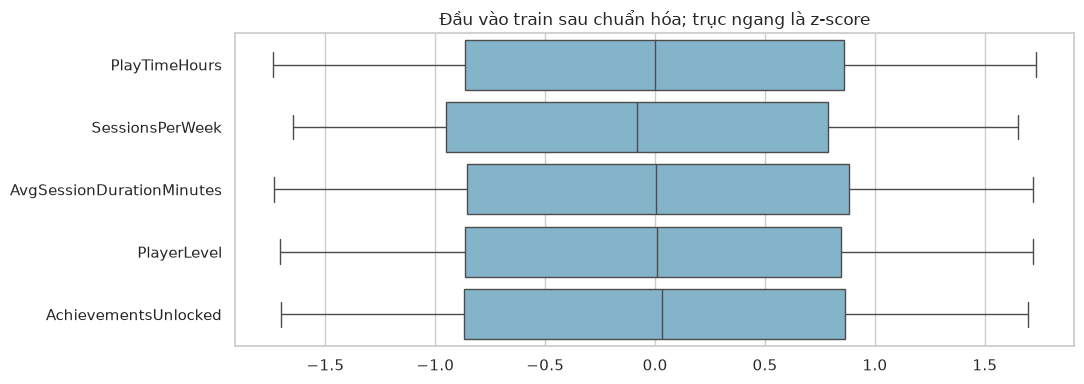

['C:\\Bop\\New folder\\gamer_profiling\\outputs\\notebook\\validation_bd40b6e5a2\\modular\\preprocessing.joblib']

In [3]:
before_after = pd.DataFrame({"mean_raw_train": X.iloc[train_idx].mean(),
                             "std_raw_train": X.iloc[train_idx].std(ddof=0),
                             "mean_scaled_train": Z_train.mean(axis=0),
                             "std_scaled_train": Z_train.std(axis=0)})
display(before_after)
plt.figure(figsize=(11, 4))
sns.boxplot(data=pd.DataFrame(Z_train, columns=FEATURES), orient="h", color="#79b8d4")
plt.title("Đầu vào train sau chuẩn hóa; trục ngang là z-score")
save_plot("04_scaled_boxplots.png")
joblib.dump({"prep": prep, "train_idx": train_idx, "test_idx": test_idx,
             "Z_train": Z_train, "Z_test": Z_test}, NBOUT / "preprocessing.joblib")

Trung bình sau chuẩn hóa gần 0 và độ lệch chuẩn gần 1 là kiểm tra trên **train**.
Holdout không bắt buộc có đúng các giá trị đó. Tệp trung gian được lưu riêng trong `outputs/notebook/`;
không ghi đè bộ kết quả dùng cho báo cáo.